# Model comparison

Roadmap step 4. How well do models predict when a group member breaks from their group's line, compared with the group-line baseline and the member's own record?

Setup (details in [docs](../docs/README.md)):

- **Target:** a position (For, Against or Abstention) different from the most common position of the member's group colleagues on the roll call. This is the realised line, so it absorbs any revolt within the group; it isn't the group's voting list, which isn't in the data, and how often the two differ is unknown.
- **Given to every model:** the realised line of every group on the roll call. Which roll calls count as contested (smaller of For and Against at least 2.5%) also comes from the final vote. So these are predictions of who breaks from a known group line, not of how a roll call turns out.
- **Two settings:**
  - **one roll call ahead:** history includes the member's positions on earlier roll calls the same day, often seconds earlier;
  - **day-ahead** (models marked "day-ahead"): history stops at the end of the previous sitting day, as if all of a day's predictions were made before the sitting.
- **Time split:** train January 2020 to June 2023, choose trees and epochs on July 2023 to July 2024, and **test on the 10th term** (16 July 2024 to October 2026).
- **Two kinds of roll call:** the member's group took the same line as most other groups, or not. These are the counterpart of the USA's bipartisan and party-opposed roll calls.

Predictions come from `run_model.py` and are read from `outputs/predictions.parquet`.

In [1]:
import sys
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

sys.path.append(str(Path.cwd().parent))
from run_model import summarise  # noqa: E402
from features import group_positions  # noqa: E402  (also puts data_loading and vote_explanation on the path)
from explanation import NON_ATTACHED, independent_party_ids  # noqa: E402
from howtheyvote import DEFAULT_MINORITY_SHARE, load, load_rollcalls, load_votes  # noqa: E402

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#8f5bd6"]
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})
LABELS = {"GUE_NGL": "The Left", "GREEN_EFA": "Greens/EFA", "SD": "S&D", "RENEW": "Renew", "EPP": "EPP",
          "ECR": "ECR", "PFE": "PfE", "ESN": "ESN"}
GROUP_ORDER = ["GREEN_EFA", "GUE_NGL", "SD", "RENEW", "EPP", "ECR", "PFE", "ESN"]
MODELS = {
    "group_line": "Group line", "training_rate": "Training rate",
    "own_past_rate": "Own past rate", "logistic": "Logistic regression", "boosting": "Gradient boosting",
    "gru_seed0": "GRU, seed 0", "gru_seed1": "GRU, seed 1", "gru_seed2": "GRU, seed 2",
    "own_past_rate_day": "Own past rate, day-ahead", "logistic_day": "Logistic regression, day-ahead",
    "boosting_day": "Gradient boosting, day-ahead", "gru_day_seed0": "GRU, day-ahead, seed 0",
    "boosting_with_split": "Boosting + group split and colleagues (after the vote)",
    "boosting_with_colleagues": "Boosting + colleagues only (after the vote)",
}

predictions = pd.read_parquet(Path.cwd().parent / "outputs" / "predictions.parquet")
ordered = predictions.sort_values(["member_id", "timestamp", "vote_id"])
first = (ordered["member_id"] != ordered["member_id"].shift()) | (ordered["date"] != ordered["date"].shift())
predictions["first_of_day"] = first.reindex(predictions.index).to_numpy()
test = predictions[predictions["split"] == "test"].reset_index(drop=True)
print(f"Test: {len(test):,} positions on {test['vote_id'].nunique():,} roll calls by {test['member_id'].nunique():,} members "
      f"on {test['date'].nunique()} sitting days; defection rate {test['defected'].mean():.4f}")

Test: 3,732,907 positions on 6,226 roll calls by 715 members on 113 sitting days; defection rate 0.0813


## How the data are laid out in time

Roll calls on a sitting day follow each other quickly, so "earlier information" can be seconds old. Also the base rates per period, since the time split moves them.

In [2]:
rollcalls = load_rollcalls()
calls = (rollcalls[rollcalls["vote_id"].isin(test["vote_id"].unique())]
         .sort_values(["timestamp", "vote_id"]).reset_index(drop=True))
same_day = calls["date"].eq(calls["date"].shift())
gap = calls["timestamp"].diff().dt.total_seconds()[same_day]
print(f"Consecutive test roll calls on the same day: {same_day.sum():,}; seconds apart, quartiles "
      f"{gap.quantile(0.25):.0f} / {gap.quantile(0.5):.0f} / {gap.quantile(0.75):.0f}")
for column in ["reference", "procedure_reference"]:
    same = calls[column].notna() & calls[column].eq(calls[column].shift()) & same_day
    print(f"  share with the same {column} as the previous roll call: {same.sum() / same_day.sum():.3f}")
ties = calls.groupby("timestamp").size()
print(f"Roll calls sharing a timestamp with another: {int(ties[ties > 1].sum())} of {len(calls):,}")
member_gap = (ordered["timestamp"].diff().dt.total_seconds()
              [(ordered["member_id"] == ordered["member_id"].shift()) & (ordered["date"] == ordered["date"].shift())])
print(f"A member's consecutive positions on the same day (validation and test), median seconds apart: {member_gap.median():.0f}")
print(f"Positions that are a member's first of the day, test: {test['first_of_day'].mean():.3f}")

rows = pd.read_parquet(Path.cwd().parent / "outputs" / "rows.parquet", columns=["date", "defected", "with_most_groups"])
bounds = {"train": ("2020-01-01", "2023-07-01"), "validation": ("2023-07-01", "2024-07-16"), "test": ("2024-07-16", "2100-01-01")}
display(pd.DataFrame({name: {"positions": int(((rows["date"] >= a) & (rows["date"] < b)).sum()),
                             "defection rate": rows.loc[(rows["date"] >= a) & (rows["date"] < b), "defected"].mean(),
                             "share with most groups": rows.loc[(rows["date"] >= a) & (rows["date"] < b), "with_most_groups"].mean()}
                      for name, (a, b) in bounds.items()}).T.round(4))
del rows

Consecutive test roll calls on the same day: 6,113; seconds apart, quartiles 11 / 14 / 23
  share with the same reference as the previous roll call: 0.889
  share with the same procedure_reference as the previous roll call: 0.892
Roll calls sharing a timestamp with another: 2 of 6,226


A member's consecutive positions on the same day (validation and test), median seconds apart: 15
Positions that are a member's first of the day, test: 0.017


,positions,defection rate,share with most groups
train,9043285.0,0.0846,0.7382
validation,1731467.0,0.0983,0.7167
test,3732907.0,0.0813,0.6289


- **Roll calls come in fast runs on the same texts.** Consecutive roll calls on a test sitting day are a median 14 seconds apart (quartiles 11 and 23), and 89% share the previous roll call's reference. A member's consecutive positions on the same day are a median 15 seconds apart. Only 1.7% of test positions are a member's first of the day.
- **Timestamp ties are negligible:** 2 of 6,226 test roll calls share a timestamp, so the order of earlier roll calls is almost never arbitrary.
- **The base rate moves with the split:** defection is 8.5% in training, 9.8% in validation and 8.1% in the test term. The share of positions where the group took the line of most other groups falls from 74% to 72% to 63%, so the test term has more roll calls where groups split from the majority of groups.

## What the close-split filter removes

Rows are dropped when the member's group, counting the member, splits by 0 or 1 votes between its two most common positions. Counted against the line without the member, as in the target.

In [3]:
contested = rollcalls.loc[~rollcalls["is_secret"] & (rollcalls["minority_share"] >= DEFAULT_MINORITY_SHARE), "vote_id"]
votes = pd.concat([load_votes(t) for t in [9, 10]], ignore_index=True)
votes = votes[votes["vote_id"].isin(contested)][["vote_id", "member_id", "position", "group_code", "country_code", "national_party_id"]]
lines = group_positions(votes, independent_party_ids(load("national_parties")))
del votes
lines = lines[(lines["group_code"] != NON_ATTACHED) & (lines["own_line"] >= 0)][["vote_id", "position_code", "own_line", "own_full_margin"]]
lines = lines.merge(rollcalls[["vote_id", "date"]], on="vote_id")
lines["defected"] = lines["position_code"] != lines["own_line"]
lines["close"] = lines["own_full_margin"] <= 1
lines["period"] = pd.cut(lines["date"], pd.to_datetime(["2019-01-01", "2020-01-01", "2023-07-01", "2024-07-16", "2100-01-01"]),
                         labels=["2019 (history only)", "train", "validation", "test"], right=False)
close = lines.groupby("period", observed=True).apply(lambda p: pd.Series({
    "positions with a line": len(p), "share dropped": p["close"].mean(),
    "defections": int(p["defected"].sum()), "share of defections dropped": (p["close"] & p["defected"]).sum() / p["defected"].sum(),
    "defection rate kept": p.loc[~p["close"], "defected"].mean(), "defection rate without the filter": p["defected"].mean()}),
    include_groups=False)
display(close.round(4))
del lines

,positions with a line,share dropped,defections,share of defections dropped,defection rate kept,defection rate without the filter
period,,,,,,
2019 (history only),304962.0,0.0010,26417.0,0.0118,0.0857,0.0866
train,9070039.0,0.0029,791783.0,0.0338,0.0846,0.0873
validation,1738261.0,0.0039,177008.0,0.0384,0.0983,0.1018
test,3741919.0,0.0024,312503.0,0.0288,0.0813,0.0835


The filter removes few positions (0.24% of test positions with a line) but disproportionately many defections (2.9% of test defections, 3.4% in training). Without it, the test defection rate would be 8.35% instead of 8.13%. In close groups it keeps loyal members and drops defectors, so the target slightly understates defection where groups were almost evenly split. The alternative filter on the others' margin would instead keep only the minority side of every 1-vote split, all labelled as defectors. This filter matches the USA. A ranking of models over 99.8% of positions is unlikely to depend on it, but that wasn't tested by refitting.

## Test results

In [4]:
subsets = {"all positions": np.ones(len(test), bool), "group with most groups": test["with_most_groups"].to_numpy(),
           "group against most groups": ~test["with_most_groups"].to_numpy(), "first position of the day": test["first_of_day"].to_numpy()}
tables = {}
for label, mask in subsets.items():
    part = test[mask]
    with warnings.catch_warnings():  # the against-most column is empty within the with-most subset
        warnings.simplefilter("ignore", RuntimeWarning)
        tables[label] = pd.DataFrame({MODELS[m]: summarise(part, part[f"p_{m}"].to_numpy()) for m in MODELS}).T
    tables[label].loc[:, "defection_rate"] = part["defected"].mean()
display(tables["all positions"].drop(columns="defection_log_loss").round(4))
for label in ["group with most groups", "group against most groups"]:
    print(label)
    display(tables[label][["line_accuracy", "defection_auc", "defection_average_precision", "defection_rate"]].round(4))

,line_accuracy,line_accuracy_against_most,defection_auc,defection_average_precision,defections_caught,flag_precision,defection_rate
Group line,0.9187,0.8886,0.5000,0.0813,0.0000,0.0000,0.0813
Training rate,0.9187,0.8886,0.5000,0.0813,0.0000,0.0000,0.0813
Own past rate,0.9186,0.8884,0.7260,0.2017,0.0092,0.4610,0.0813
Logistic regression,0.9203,0.8919,0.7990,0.3248,0.0999,0.5532,0.0813
Gradient boosting,0.9211,0.8935,0.8017,0.3315,0.0995,0.5874,0.0813
"GRU, seed 0",0.9262,0.9005,0.8393,0.4247,0.2171,0.6340,0.0813
"GRU, seed 1",0.9258,0.8996,0.8376,0.4186,0.2023,0.6369,0.0813
"GRU, seed 2",0.9255,0.8995,0.8344,0.4153,0.2113,0.6230,0.0813
"Own past rate, day-ahead",0.9182,0.8877,0.7184,0.1914,0.0092,0.3680,0.0813
"Logistic regression, day-ahead",0.9176,0.8884,0.7336,0.2278,0.0341,0.4177,0.0813


group with most groups


,line_accuracy,defection_auc,defection_average_precision,defection_rate
Group line,0.9364,0.5000,0.0636,0.0636
Training rate,0.9364,0.5000,0.0636,0.0636
Own past rate,0.9364,0.7368,0.1891,0.0636
Logistic regression,0.9370,0.7950,0.2956,0.0636
Gradient boosting,0.9374,0.7997,0.2912,0.0636
"GRU, seed 0",0.9413,0.8393,0.3901,0.0636
"GRU, seed 1",0.9412,0.8401,0.3901,0.0636
"GRU, seed 2",0.9408,0.8376,0.3818,0.0636
"Own past rate, day-ahead",0.9361,0.7293,0.1792,0.0636
"Logistic regression, day-ahead",0.9348,0.7226,0.1887,0.0636


group against most groups


,line_accuracy,defection_auc,defection_average_precision,defection_rate
Group line,0.8886,0.5000,0.1114,0.1114
Training rate,0.8886,0.5000,0.1114,0.1114
Own past rate,0.8884,0.6734,0.2101,0.1114
Logistic regression,0.8919,0.7815,0.3602,0.1114
Gradient boosting,0.8935,0.7837,0.3675,0.1114
"GRU, seed 0",0.9005,0.8229,0.4566,0.1114
"GRU, seed 1",0.8996,0.8178,0.4454,0.1114
"GRU, seed 2",0.8995,0.8149,0.4465,0.1114
"Own past rate, day-ahead",0.8877,0.6646,0.1994,0.1114
"Logistic regression, day-ahead",0.8884,0.7154,0.2712,0.1114


**The 10th term** has 3.7 million positions on 6,226 roll calls by 715 members, over 113 sitting days. 8.1% of positions break from the group line: 6.4% where the group took the line of most other groups and 11.1% where it didn't.

**One roll call ahead** (history up to the previous roll call):

- **Line accuracy barely moves, because defections are rare.** The group line alone is right on 91.9% of positions (88.9% where the group went against most groups). The best model, the GRU, reaches 92.6% (90.0%). At a 0.5 threshold it flags about 21% of defections, and 62% to 64% of its flags are right.
- **Ranking defections.** Defection AUC rises from 0.726 for the member's own past rate to 0.799 for logistic regression, 0.802 for boosting and 0.834 to 0.839 for the three GRU seeds. Average precision, against a base rate of 0.081, rises from 0.202 to 0.325, 0.332 and 0.415 to 0.425.
- **Both kinds of roll call** show the same pattern: own past rate, then logistic regression and boosting about equal, then the GRU. Where the group went against most groups, the GRU's AUC is 0.815 to 0.823; elsewhere it is 0.838 to 0.840.

**Day-ahead** (history up to the end of the previous sitting day):

- **Little is left beyond the member's own record.** AUC is 0.718 for the own past rate, 0.734 for logistic regression and 0.730 for boosting. Average precision is 0.191, 0.228 and 0.230.
- **The day-ahead GRU does worse than the own past rate** (AUC 0.698, average precision 0.192), so this design of it doesn't work. It is one seed of one design, in which the previous day's outcomes arrive as three rates at the day's first position.
- **No day-ahead model beats the group line on line accuracy.** Boosting is at 91.96% against 91.87%, and the others are at or below it.

**After the vote** (upper references, not forecasts):

- Adding how split the group was (counting the member, so it partly contains the answer) and what national colleagues in the group did gives AUC 0.967 and average precision 0.827.
- Colleagues alone give 0.942 and 0.764. What national colleagues did on the same roll call is strongly associated with defection, as in the explanation step, and isn't known before the vote.

## Are the steps larger than chance?

A two-way bootstrap: each draw resamples sitting days and members together, weighting each position by how often its day and its member were drawn. Days rather than roll calls, because roll calls on the same day are runs of votes on the same texts and aren't independent. 1,000 draws, as in the USA. Differences in AUC and average precision between models, over all positions, for each kind of roll call, and on members' first positions of the day. GRU seeds 1 and 2 aren't bootstrapped; the seeds differ by at most 0.005 in AUC.

In [5]:
class Ranked:
    """Scores sorted once, so each bootstrap draw only reweights. Per distinct score, the weighted positives and
    totals give both AUC (ties counted half) and average precision (stepping at each distinct score, as scikit-learn
    does). index maps sorted positions to rows of the whole test table."""

    def __init__(self, rows, score, y):
        order = np.argsort(score, kind="mergesort")
        self.index = rows[order]
        sorted_score = score[order]
        self.starts = np.flatnonzero(np.r_[True, sorted_score[1:] != sorted_score[:-1]])
        self.y = y[order]

    def both(self, w):
        ww = w[self.index]
        pos = np.add.reduceat(ww * self.y, self.starts)
        neg = np.add.reduceat(ww, self.starts) - pos
        below = np.cumsum(neg) - neg
        auc = (pos * (below + neg / 2)).sum() / (pos.sum() * neg.sum())
        tp, fp = np.cumsum(pos[::-1]), np.cumsum(neg[::-1])
        ap = np.sum(pos[::-1] / tp[-1] * tp / np.maximum(tp + fp, 1e-12))
        return float(auc), float(ap)


y = test["defected"].to_numpy().astype(float)
ladder = ["own_past_rate", "logistic", "boosting", "gru_seed0", "own_past_rate_day", "logistic_day", "boosting_day", "gru_day_seed0"]
ranked = {(label, m): Ranked(np.flatnonzero(mask), test.loc[mask, f"p_{m}"].to_numpy(), y[mask])
          for label, mask in subsets.items() for m in ladder}
ones = np.ones(len(test))
for m in ["boosting", "gru_day_seed0"]:
    auc, ap = ranked[("all positions", m)].both(ones)
    assert abs(auc - roc_auc_score(y, test[f"p_{m}"])) < 1e-6
    assert abs(ap - average_precision_score(y, test[f"p_{m}"])) < 1e-6

pool = ThreadPoolExecutor(8)
rng = np.random.default_rng(0)
days, day_index = np.unique(test["date"], return_inverse=True)
people, person_index = np.unique(test["member_id"], return_inverse=True)
draws = []
for _ in range(1000):
    w = (np.bincount(rng.integers(0, len(days), len(days)), minlength=len(days))[day_index]
         * np.bincount(rng.integers(0, len(people), len(people)), minlength=len(people))[person_index]).astype(float)
    results = pool.map(lambda r: r.both(w), ranked.values())  # NumPy releases the GIL, so threads run in parallel
    row = {}
    for (label, m), (auc, ap) in zip(ranked, results):
        row[(label, m, "auc")], row[(label, m, "ap")] = auc, ap
    draws.append(row)
pool.shutdown()
draws = pd.DataFrame(draws)
steps = [("logistic", "own_past_rate"), ("boosting", "logistic"), ("gru_seed0", "boosting"),
         ("logistic_day", "own_past_rate_day"), ("boosting_day", "logistic_day"), ("gru_day_seed0", "boosting_day"),
         ("boosting_day", "own_past_rate_day"), ("own_past_rate", "own_past_rate_day"), ("boosting", "boosting_day"),
         ("gru_seed0", "gru_day_seed0")]
rows_out = {}
for label in subsets:
    for better, worse in steps:
        for metric in ["auc", "ap"]:
            diff = draws[(label, better, metric)] - draws[(label, worse, metric)]
            rows_out[(label, f"{MODELS[better]} over {MODELS[worse]}", metric)] = diff.quantile([0.025, 0.5, 0.975]).to_numpy()
intervals = pd.DataFrame(rows_out, index=["2.5%", "median", "97.5%"]).T
with pd.option_context("display.max_rows", 200):
    display(intervals.round(4))

2.5%  \
all positions             Logistic regression over Own past rate             auc  0.0626   
                                                                             ap   0.1101   
                          Gradient boosting over Logistic regression         auc -0.0012   
                                                                             ap  -0.0020   
                          GRU, seed 0 over Gradient boosting                 auc  0.0333   
                                                                             ap   0.0805   
                          Logistic regression, day-ahead over Own past ra... auc  0.0087   
                                                                             ap   0.0288   
                          Gradient boosting, day-ahead over Logistic regr... auc -0.0101   
                                                                             ap  -0.0103   
                          GRU, day-ahead, seed 0 over Gradient boosting, ... auc -0.0396   
                                                                             ap  -0.0490   
                          Gradient boosting, day-ahead over Own past rate... auc  0.0022   
                                                                             ap   0.0251   
                          Own past rate over Own past rate, day-ahead        auc  0.0050   
                                                                             ap   0.0057   
                          Gradient boosting over Gradient boosting, day-a... auc  0.0628   
                                                                             ap   0.0870   
                          GRU, seed 0 over GRU, day-ahead, seed 0            auc  0.1282   
                                                                             ap   0.2077   
group with most groups    Logistic regression over Own past rate             auc  0.0440   
                                                                             ap   0.0893   
                          Gradient boosting over Logistic regression         auc -0.0008   
                                                                             ap  -0.0162   
                          GRU, seed 0 over Gradient boosting                 auc  0.0333   
                                                                             ap   0.0856   
                          Logistic regression, day-ahead over Own past ra... auc -0.0156   
                                                                             ap   0.0019   
                          Gradient boosting, day-ahead over Logistic regr... auc -0.0103   
                                                                             ap  -0.0281   
                          GRU, day-ahead, seed 0 over Gradient boosting, ... auc -0.0386   
                                                                             ap  -0.0424   
                          Gradient boosting, day-ahead over Own past rate... auc -0.0196   
                                                                             ap  -0.0192   
                          Own past rate over Own past rate, day-ahead        auc  0.0048   
                                                                             ap   0.0050   
                          Gradient boosting over Gradient boosting, day-a... auc  0.0671   
                                                                             ap   0.0986   
                          GRU, seed 0 over GRU, day-ahead, seed 0            auc  0.1303   
                                                                             ap   0.2167   
group against most groups Logistic regression over Own past rate             auc  0.0949   
                                                                             ap   0.1338   
                          Gradient boosting over Logistic regression         auc -0.0028   
                                    

95% intervals from 1,000 two-way draws of sitting days and members. Resampling days instead of roll calls widens them.

**One roll call ahead:**
- Logistic regression over the own past rate: AUC +0.073 (+0.063 to +0.085), clear in every subset except first positions of the day.
- Boosting over logistic regression: AUC +0.003 (−0.001 to +0.007). **Not established**, overall or in either subset. With roll calls resampled instead of days, the overall interval was just above zero.
- GRU over boosting: AUC +0.038 (+0.033 to +0.042) and average precision +0.093 (+0.081 to +0.106). Clear on both kinds of roll call.

**Day-ahead:**
- Logistic regression over the own past rate: AUC +0.015 (+0.009 to +0.022) and average precision +0.037 (+0.029 to +0.046). Boosting over the own past rate: AUC +0.011 (+0.002 to +0.020).
- The gain comes only from roll calls where the group went against most groups: boosting over the own past rate gives +0.045 (+0.034 to +0.058) there, against −0.008 (−0.020 to +0.004) elsewhere.
- The day-ahead GRU is worse than day-ahead boosting: AUC −0.032 (−0.040 to −0.024).

**What the same sitting day adds:**
- Boosting gains +0.072 AUC (+0.063 to +0.083) from same-day history, and the GRU +0.14 over its day-ahead version.
- The own past rate gains only +0.008: the member's overall rate barely changes within a day. What matters is the recent run of outcomes.

**First positions of the day** (65,000 positions): no step is established. Logistic regression over the own past rate is −0.004 (−0.028 to +0.019), and the GRU over boosting is −0.007 (−0.025 to +0.010). The intervals reach about ±0.02; the GRU's gain over boosting there is at most 0.01.

The intervals hold the fitted models fixed, so they don't include refit variation (seed, early stopping). The three one-roll-call-ahead GRU seeds differ by 0.005 in AUC; the day-ahead GRU has one seed.

## First position of the day or later

A member's first position of a sitting day is the one place where the one-roll-call-ahead models have no same-day history either.

In [6]:
day_models = ["own_past_rate", "logistic", "boosting", "gru_seed0", "own_past_rate_day", "boosting_day", "gru_day_seed0"]
day_table = test.groupby("first_of_day").apply(lambda part: pd.Series({
    "positions": len(part), "defection_rate": part["defected"].mean(),
    **{f"AUC {MODELS[m]}": roc_auc_score(part["defected"], part[f"p_{m}"]) for m in day_models},
    **{f"AP {MODELS[m]}": average_precision_score(part["defected"], part[f"p_{m}"]) for m in day_models}}),
    include_groups=False)
day_table.index = day_table.index.map({True: "first position of the day", False: "later positions"})
display(day_table.T.round(3))

first_of_day,later positions,first position of the day
positions,3668006.000,64901.000
defection_rate,0.081,0.078
AUC Own past rate,0.726,0.704
AUC Logistic regression,0.801,0.699
AUC Gradient boosting,0.803,0.703
"AUC GRU, seed 0",0.841,0.696
"AUC Own past rate, day-ahead",0.719,0.704
"AUC Gradient boosting, day-ahead",0.730,0.716
"AUC GRU, day-ahead, seed 0",0.698,0.687
AP Own past rate,0.203,0.170


- On a member's first position of the day, the one-roll-call-ahead models are back at the level of the own past rate: AUC 0.696 to 0.704, and average precision 0.170 to 0.183. Day-ahead boosting is at 0.716 and 0.205, and the bootstrap separates it from the own past rate there on average precision (+0.009 to +0.065) but not on AUC (−0.009 to +0.033).
- Every model ranks first positions worse than later ones, including day-ahead models, which are equally blind on both. So first positions may differ in kind, for example as the opening votes of a session, and they're only 1.7% of positions. The day-ahead models, scored on every position, are the cleaner test of prediction before a sitting.

## Over time and by group

Single fitted models without intervals. The validation half-years were used to choose trees and epochs, so they flatter the models slightly.

In [7]:
over_time = ["own_past_rate", "boosting", "gru_seed0", "boosting_day", "gru_day_seed0"]
periods = predictions.assign(half=predictions["date"].dt.year + (predictions["date"].dt.month > 6) * 0.5)
by_half = periods.groupby("half").apply(lambda part: pd.Series({
    "positions": len(part), "defection_rate": part["defected"].mean(),
    **{MODELS[m]: roc_auc_score(part["defected"], part[f"p_{m}"]) for m in over_time}}),
    include_groups=False)
by_half.index = [f"{int(h)} {'H2' if h % 1 else 'H1'}" for h in by_half.index]
print("AUC by half-year (validation, then test):")
display(by_half.round(3))
by_group = test.groupby("group_code").apply(lambda part: pd.Series({
    "positions": len(part), "defection_rate": part["defected"].mean(),
    **{f"AUC {MODELS[m]}": roc_auc_score(part["defected"], part[f"p_{m}"]) for m in over_time},
    **{f"AP {MODELS[m]}": average_precision_score(part["defected"], part[f"p_{m}"]) for m in ["boosting", "gru_seed0", "boosting_day", "gru_day_seed0"]}}),
    include_groups=False)
print("Test, by group:")
display(by_group.reindex([g for g in GROUP_ORDER if g in by_group.index]).rename(index=LABELS).T.round(3))

AUC by half-year (validation, then test):


,positions,defection_rate,Own past rate,Gradient boosting,"GRU, seed 0","Gradient boosting, day-ahead","GRU, day-ahead, seed 0"
2023 H2,886562.0,0.095,0.710,0.823,0.851,0.769,0.728
2024 H1,844905.0,0.102,0.701,0.820,0.848,0.743,0.714
2024 H2,288866.0,0.099,0.729,0.799,0.830,0.727,0.676
2025 H1,799116.0,0.082,0.739,0.799,0.834,0.736,0.706
2025 H2,906860.0,0.079,0.721,0.816,0.855,0.730,0.697
2026 H1,1077997.0,0.082,0.722,0.796,0.832,0.728,0.698
2026 H2,660068.0,0.075,0.721,0.793,0.837,0.723,0.700


Test, by group:


group_code,Greens/EFA,The Left,S&D,Renew,EPP,ECR,PfE,ESN
positions,295576.000,239482.000,732169.000,417159.000,1005221.000,438819.000,456967.000,147514.000
defection_rate,0.042,0.079,0.047,0.058,0.075,0.124,0.151,0.096
AUC Own past rate,0.749,0.691,0.684,0.712,0.718,0.661,0.629,0.780
AUC Gradient boosting,0.826,0.771,0.781,0.785,0.809,0.741,0.731,0.850
"AUC GRU, seed 0",0.849,0.807,0.832,0.828,0.844,0.786,0.793,0.877
"AUC Gradient boosting, day-ahead",0.759,0.717,0.673,0.711,0.729,0.679,0.659,0.769
"AUC GRU, day-ahead, seed 0",0.701,0.685,0.657,0.640,0.703,0.657,0.643,0.625
AP Gradient boosting,0.300,0.299,0.257,0.281,0.332,0.368,0.356,0.400
"AP GRU, seed 0",0.355,0.371,0.361,0.368,0.436,0.442,0.451,0.509
"AP Gradient boosting, day-ahead",0.178,0.219,0.108,0.148,0.193,0.302,0.300,0.253


- **Over time:** one-roll-call-ahead models drop by about 0.02 AUC from the validation half-years to the first half-year of the 10th term (GRU 0.848 to 0.851, then 0.830; boosting 0.82, then 0.80), then hold steady (GRU 0.830 to 0.855). Day-ahead boosting falls from 0.769 and 0.743 to 0.723 to 0.736. The validation half-years were used to choose trees and epochs, so part of the drop is that choice, not the new term. The models don't use group identity, and the new groups (PfE, ESN) don't break them.
- **By group, one roll call ahead:** the GRU ranks defections better than boosting in every group. AUC is lowest in ECR (0.786) and PfE (0.793), which have the highest defection rates (12.4% and 15.1%), and highest in ESN (0.877).
- **By group, day-ahead:** boosting is close to the one-roll-call-ahead own past rate in most groups and below it in S&D (0.673 against 0.684) and ESN (0.769 against 0.780). The day-ahead GRU is weakest in ESN (0.625).
- These are single fitted models without intervals. Average precision depends on each group's base rate, so it shouldn't be compared across groups.

## Calibration

Mean predicted probability against the observed defection rate, in ten bins of predicted probability, test term.

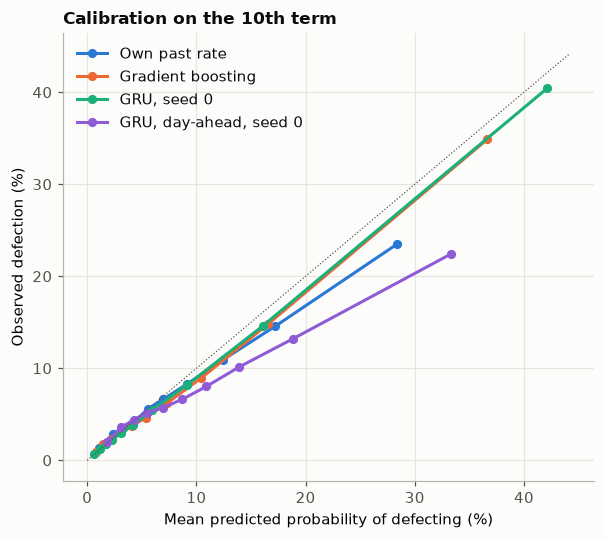

Mean prediction against observed rate: {'Own past rate': 0.0905, 'Gradient boosting': 0.0879, 'GRU, seed 0': 0.0864, 'GRU, day-ahead, seed 0': 0.1074} observed 0.0813


In [8]:
fig, axis = plt.subplots(figsize=(5.6, 5))
calibrated = ["own_past_rate", "boosting", "gru_seed0", "gru_day_seed0"]
for m, color in zip(calibrated, SERIES):
    p = test[f"p_{m}"]
    bins = pd.qcut(p.rank(method="first"), 10, labels=False)
    table = test.groupby(bins).agg(predicted=(f"p_{m}", "mean"), observed=("defected", "mean"))
    axis.plot(table["predicted"] * 100, table["observed"] * 100, marker="o", markersize=5, color=color, label=MODELS[m])
limit = max(axis.get_xlim()[1], axis.get_ylim()[1])
axis.plot([0, limit], [0, limit], color=NEUTRAL, linewidth=0.8, linestyle=":")
axis.set_xlabel("Mean predicted probability of defecting (%)")
axis.set_ylabel("Observed defection (%)")
axis.set_title("Calibration on the 10th term")
axis.legend(loc="upper left")
fig.tight_layout()
plt.show()
print("Mean prediction against observed rate:",
      {MODELS[m]: round(float(test[f"p_{m}"].mean()), 4) for m in calibrated},
      "observed", round(float(test["defected"].mean()), 4))

- The one-roll-call-ahead models are close to the diagonal and slightly too high: mean predictions are 0.086 to 0.091 against 0.081 observed. Defection was more common in training and validation (8.5% and 9.8%) than in the test term, so this is mostly a level shift from the time split.
- The own past rate is too high in its top bin (28% predicted, 23% observed).
- The day-ahead GRU is clearly too high (mean 0.107, top bin 33% predicted against 22% observed), another sign that this design of it doesn't work.

## Compared with the USA

Both entities use the same ladder and the same kind of split. The definitions differ: the USA predicts Yea or Nay against the party majority in a two-party chamber; here three positions against a group plurality without the member, in a multi-party chamber, on two terms instead of decades. So levels are comparable only loosely. The USA models are one roll call ahead; no day-ahead version was fitted there.

In [9]:
usa = pd.DataFrame({
    "USA AUC": [0.500, 0.773, 0.831, 0.850, "0.854 to 0.858"],
    "USA average precision": [0.064, 0.270, 0.362, 0.379, "0.401 to 0.409"],
}, index=["Group or party line", "Own past rate", "Logistic regression", "Gradient boosting", "GRU"])
main = tables["all positions"]


def column(metric, day=False):
    suffix = ", day-ahead" if day else ""
    values = [main.loc["Group line", metric]] + [main.loc[f"{name}{suffix}", metric] for name in
                                                 ["Own past rate", "Logistic regression", "Gradient boosting"]]
    if day:
        return values + [main.loc["GRU, day-ahead, seed 0", metric]]
    gru = [main.loc[f"GRU, seed {s}", metric] for s in range(3)]
    return values + [f"{min(gru):.3f} to {max(gru):.3f}"]


usa["EP AUC"], usa["EP average precision"] = column("defection_auc"), column("defection_average_precision")
usa["EP day-ahead AUC"], usa["EP day-ahead average precision"] = column("defection_auc", True), column("defection_average_precision", True)
display(usa.map(lambda v: round(v, 3) if isinstance(v, float) else v))
print("USA figures: usa/pipeline/vote_prediction/docs/README.md (test 2015 to 2024, GRU single seeds). EP day-ahead GRU: seed 0.")

,USA AUC,USA average precision,EP AUC,EP average precision,EP day-ahead AUC,EP day-ahead average precision
Group or party line,0.5,0.064,0.5,0.081,0.500,0.081
Own past rate,0.773,0.27,0.726,0.202,0.718,0.191
Logistic regression,0.831,0.362,0.799,0.325,0.734,0.228
Gradient boosting,0.85,0.379,0.802,0.332,0.730,0.230
GRU,0.854 to 0.858,0.401 to 0.409,0.834 to 0.839,0.415 to 0.425,0.698,0.192


USA figures: usa/pipeline/vote_prediction/docs/README.md (test 2015 to 2024, GRU single seeds). EP day-ahead GRU: seed 0.


- **One roll call ahead, the order is close to the USA's:** own past rate, then the feature models, then the GRU. Two differences: boosting doesn't beat logistic regression here (in the USA it adds 0.019 AUC), and the GRU's gain over boosting is larger here (0.031 to 0.040 AUC against 0.004 to 0.008).
- **The European Parliament's GRU gain comes from same-day history.** Roll calls run a median 14 seconds apart, mostly on the same texts. Whether the USA's models rest on same-day history in the same way wasn't checked: no day-ahead version was fitted there.
- **Levels aren't comparable.** The targets differ (three positions against a group plurality without the member, against Yea or Nay against the party majority), and so do base rates (8.1% against 6.4%) and periods. So the lower European Parliament AUCs aren't evidence that its defections are harder to predict.

## Summary

- **One roll call ahead within a sitting, given every group's realised line,** the GRU ranks who will break from their group's line best on the 10th term: AUC 0.834 to 0.839 and average precision 0.415 to 0.425. Boosting gets 0.802 and 0.332, logistic regression 0.799 and 0.325, and the member's own past rate 0.726 and 0.202. Logistic regression over the own past rate and the GRU over boosting are clearly larger than chance in a bootstrap of sitting days and members. Boosting over logistic regression isn't established.
- **Day-ahead, the fitted models add little to the member's own record:** AUC 0.730 to 0.734 against 0.718, all of it on roll calls where the group went against most groups. The day-ahead GRU, as designed, is worse than the own past rate. No day-ahead model meaningfully beats the group line on line accuracy.
- **So most of what the models predict beyond a member's record is persistence within a sitting.** A member who has just broken from the group line tends to keep doing so on the next roll calls of the same sitting, which are seconds apart and mostly runs of votes on the same text. Same-text persistence isn't separated here from persistence within a sitting in general.
- **Line accuracy improves little** (91.9% for the group line, 92.6% for the GRU), because defections are 8% of positions.
- **What national colleagues did on the same roll call** gives AUC 0.942 on its own. It is strongly associated with defection, and isn't available before the vote.
- **Limits:**
  - all models are conditional on the realised group lines;
  - the target is a break from the realised plurality, not from the voting list;
  - the test is one term with new groups;
  - intervals don't include refit variation, and the day-ahead GRU has one seed;
  - the close-split filter removes about 3% of defections;
  - these are associations in a selected sample of roll calls.